# Retail Banking — Feature Engineering, Pre-processing & Splitting

**Module:** Build an AI Model to Forecast Trends and Detect Opportunities in Retail Banking

This notebook prepares the cleaned retail banking data for predictive modeling. It selects and creates features based on banking behavior, converts text columns to numbers, scales the numeric columns, defines a target, splits the data into training and test sets, and forecasts monthly transactions for the next 6 months.

**Data used:** retail_banking_customers.csv (5,000 customers, 10 columns) and retail_banking_transactions.csv (24,000 rows, 1,000 customers, 24 months).

**Outputs:** the pre-processed dataset (preprocessed_dataset.csv) and this summary.

In [1]:
import numpy as np
import pandas as pd

In [2]:
customers = pd.read_csv("retail_banking_customers.csv")

transactions = pd.read_csv("retail_banking_transactions.csv")

print(customers.shape)
print(transactions.shape)

(5000, 10)
(24000, 3)


In [3]:
customers.head()

,customer_id,age,region,preferred_channel,monthly_transactions_avg,avg_monthly_balance,num_products_held,digital_adoption_score,credit_card_issued,loan_taken
0,CUST100000,56,North,ATM,29,36460,1,0.56,0,0
1,CUST100001,69,South,Branch,15,54595,3,0.74,1,0
2,CUST100002,46,West,Online Banking,12,55180,3,0.08,0,0
3,CUST100003,32,North,Branch,23,50150,2,0.52,0,0
4,CUST100004,60,Central,Online Banking,18,61720,2,0.62,1,0


In [4]:
print("Missing values:")
print(customers.isnull().sum())

print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())

print(customers.dtypes)

Missing values:
customer_id                 0
age                         0
region                      0
preferred_channel           0
monthly_transactions_avg    0
avg_monthly_balance         0
num_products_held           0
digital_adoption_score      0
credit_card_issued          0
loan_taken                  0
dtype: int64
Duplicate customer IDs: 0
customer_id                     str
age                           int64
region                          str
preferred_channel               str
monthly_transactions_avg      int64
avg_monthly_balance           int64
num_products_held             int64
digital_adoption_score      float64
credit_card_issued            int64
loan_taken                    int64
dtype: object


## Feature Selection

Before creating new features, I reviewed every column in the cleaned customer dataset. I asked two questions for each column: does it show real customer behavior, and could it be weak or repeated information?

### Column review

| Column | Decision | Reason |
|---|---|---|
| customer_id | Drop from model | It is only a label to identify a customer. It does not show any behavior. I will keep it only to join tables. |
| age | Keep | Customers of different age groups use banking services in different ways. |
| region | Keep (needs encoding) | Customer behavior can change from region to region. It is text, so I will convert it to numbers later. |
| preferred_channel | Keep (needs encoding) | It shows how the customer likes to interact with the bank. It is also text, so I will convert it later. |
| monthly_transactions_avg | Keep | This is the main measure of customer activity. |
| avg_monthly_balance | Keep | This is the main measure of customer value. |
| num_products_held | Keep | A customer with more products is usually more engaged with the bank. |
| digital_adoption_score | Keep | It shows how much the customer uses digital services. |
| credit_card_issued | Keep | It shows product ownership. |
| loan_taken | Target (chosen later in this notebook) | This is the outcome I plan to predict. I will not use it as an input feature, to avoid data leakage. |

### Core feature groups

- **Customer activity:** monthly_transactions_avg, digital_adoption_score
- **Balance / value:** avg_monthly_balance
- **Product ownership / engagement:** num_products_held, credit_card_issued
- **Customer profile:** age, region, preferred_channel

### Redundancy check

I checked the correlation between all numeric columns. All the values were close to zero. This means no two features carry the same information, so I do not need to remove any feature for redundancy.

### Limitation

The correlation between the features and loan_taken is also very low. This means the signals in this dataset are weak, and model accuracy in later modules may be limited. This is a property of the data and not a mistake in the process.

In [5]:
num_cols = ["age", "monthly_transactions_avg", "avg_monthly_balance",
            "num_products_held", "digital_adoption_score",
            "credit_card_issued", "loan_taken"]

customers[num_cols].corr().round(2)

,age,monthly_transactions_avg,avg_monthly_balance,num_products_held,digital_adoption_score,credit_card_issued,loan_taken
age,1.00,-0.02,0.01,0.01,0.03,0.01,-0.03
monthly_transactions_avg,-0.02,1.00,0.01,-0.00,-0.01,0.02,0.01
avg_monthly_balance,0.01,0.01,1.00,0.01,0.02,0.00,-0.02
num_products_held,0.01,-0.00,0.01,1.00,0.01,0.02,-0.00
digital_adoption_score,0.03,-0.01,0.02,0.01,1.00,0.02,0.01
credit_card_issued,0.01,0.02,0.00,0.02,0.02,1.00,-0.01
loan_taken,-0.03,0.01,-0.02,-0.00,0.01,-0.01,1.00


In [6]:
df = customers.copy()

df["transactions_per_product"] = df["monthly_transactions_avg"] / df["num_products_held"]
df["balance_per_product"] = df["avg_monthly_balance"] / df["num_products_held"]
df["balance_per_transaction"] = df["avg_monthly_balance"] / df["monthly_transactions_avg"]

df[["customer_id", "monthly_transactions_avg", "avg_monthly_balance",
    "num_products_held", "transactions_per_product",
    "balance_per_product", "balance_per_transaction"]].head().round(2)

,customer_id,monthly_transactions_avg,avg_monthly_balance,num_products_held,transactions_per_product,balance_per_product,balance_per_transaction
0,CUST100000,29,36460,1,29.0,36460.00,1257.24
1,CUST100001,15,54595,3,5.0,18198.33,3639.67
2,CUST100002,12,55180,3,4.0,18393.33,4598.33
3,CUST100003,23,50150,2,11.5,25075.00,2180.43
4,CUST100004,18,61720,2,9.0,30860.00,3428.89


In [7]:
new_cols = ["transactions_per_product", "balance_per_product", "balance_per_transaction"]

print(df[new_cols].describe().round(2))
print()
print("Missing values:")
print(df[new_cols].isnull().sum())
print()
print("Infinity values:")
print(np.isinf(df[new_cols]).sum())

       transactions_per_product  balance_per_product  balance_per_transaction
count                   5000.00              5000.00                  5000.00
mean                      12.92             32299.07                  2643.00
std                        6.90             18564.73                  1041.32
min                        2.00               500.00                    41.67
25%                        7.00             17555.88                  1935.54
50%                       11.00             26944.25                  2511.76
75%                       19.00             45401.50                  3228.95
max                       36.00            107100.00                  9867.44

Missing values:
transactions_per_product    0
balance_per_product         0
balance_per_transaction     0
dtype: int64

Infinity values:
transactions_per_product    0
balance_per_product         0
balance_per_transaction     0
dtype: int64


In [8]:
df["activity_band"] = pd.cut(
    df["monthly_transactions_avg"],
    bins=[0, 16, 23, 100],
    labels=["Low", "Medium", "High"]
)

print(df["activity_band"].value_counts().reindex(["Low", "Medium", "High"]))
print()
print(df.groupby("activity_band", observed=True)["monthly_transactions_avg"].agg(["min", "max"]))

activity_band
Low       1098
Medium    2814
High      1088
Name: count, dtype: int64

               min  max
activity_band          
Low              6   16
Medium          17   23
High            24   36


## Engineered Features (so far)

| New feature | How it is made | Behavior it represents | Why it is useful |
|---|---|---|---|
| transactions_per_product | monthly_transactions_avg / num_products_held | How actively a customer uses each product they hold | A customer who holds many products but makes few transactions may be a low-engagement customer. A customer with high usage per product is deeply engaged. |
| balance_per_product | avg_monthly_balance / num_products_held | How much money sits behind each product | Shows how valuable each relationship is. The bank can find customers who could take more products. |
| balance_per_transaction | avg_monthly_balance / monthly_transactions_avg | Whether the customer is a saver (high balance, few transactions) or a spender (low balance, many transactions) | Helps separate saving behavior from spending behavior. This could point to different offers. |
| activity_band | Low (6-16), Medium (17-23), High (24-36) transactions per month | Engagement intensity in simple groups | Easy for business teams to understand and act on. Based on the 25th and 75th percentiles of the data. |

In [9]:
median_txn = df["monthly_transactions_avg"].median()
balance_75 = df["avg_monthly_balance"].quantile(0.75)

print("Median transactions:", median_txn)
print("75th percentile balance:", balance_75)

df["is_active"] = (df["monthly_transactions_avg"] >= median_txn).astype(int)
df["is_high_value"] = (df["avg_monthly_balance"] >= balance_75).astype(int)
df["high_value_low_engagement"] = ((df["is_high_value"] == 1) &
                                   (df["activity_band"] == "Low")).astype(int)

for col in ["is_active", "is_high_value", "high_value_low_engagement"]:
    print(col)
    print(df[col].value_counts().sort_index())
    print()

Median transactions: 20.0
75th percentile balance: 60218.5
is_active
is_active
0    2351
1    2649
Name: count, dtype: int64

is_high_value
is_high_value
0    3750
1    1250
Name: count, dtype: int64

high_value_low_engagement
high_value_low_engagement
0    4726
1     274
Name: count, dtype: int64



In [10]:
df["prefers_digital_channel"] = df["preferred_channel"].isin(
    ["Online Banking", "Mobile App"]
).astype(int)

channel_dummies = pd.get_dummies(df["preferred_channel"], prefix="channel", dtype=int)
df = pd.concat([df, channel_dummies], axis=1)

print(df["prefers_digital_channel"].value_counts().sort_index())
print()
print(channel_dummies.sum())
print()
print("Each customer has exactly this many channels:", channel_dummies.sum(axis=1).unique())
print("Table shape now:", df.shape)

df[["customer_id", "preferred_channel", "prefers_digital_channel"] +
   list(channel_dummies.columns)].head()

prefers_digital_channel
0    2537
1    2463
Name: count, dtype: int64

channel_ATM               1234
channel_Branch            1303
channel_Mobile App        1200
channel_Online Banking    1263
dtype: int64

Each customer has exactly this many channels: [1]
Table shape now: (5000, 22)


,customer_id,preferred_channel,prefers_digital_channel,channel_ATM,channel_Branch,channel_Mobile App,channel_Online Banking
0,CUST100000,ATM,0,1,0,0,0
1,CUST100001,Branch,0,0,1,0,0
2,CUST100002,Online Banking,1,0,0,0,1
3,CUST100003,Branch,0,0,1,0,0
4,CUST100004,Online Banking,1,0,0,0,1


## Engineered Features (flags and channel)

| New feature | How it is made | Behavior it represents | Why it is useful |
|---|---|---|---|
| is_active | 1 if monthly_transactions_avg is at or above the median (20), else 0 | Whether the customer uses the account regularly | A simple yes/no signal for engagement that models can use easily. |
| is_high_value | 1 if avg_monthly_balance is in the top 25% (60,218.5 or more), else 0 | Customers who keep large balances with the bank | These customers are the most valuable to keep and grow. |
| high_value_low_engagement | 1 if is_high_value is 1 and activity_band is Low | Customers with big balances who rarely transact | They may be at risk of leaving, or could be offered new products. There are 274 such customers. |
| prefers_digital_channel | 1 if preferred_channel is Online Banking or Mobile App | Customers who already use digital services | Helps plan digital upgrades and find customers who may be moved to digital. |
| channel_ATM, channel_Branch, channel_Mobile App, channel_Online Banking | One 0/1 column per channel | The dominant channel of each customer | Shows channel preference without suggesting that one channel is "higher" than another. |

### Note on channel features
The dataset gives only one preferred channel for each customer and no count of usage per channel. So I could not calculate true usage percentages. I used 0/1 indicator columns for the dominant channel instead.

In [11]:

text_cols = df.select_dtypes(exclude="number").columns.tolist()
print(text_cols)

['customer_id', 'region', 'preferred_channel', 'activity_band']


In [12]:
region_dummies = pd.get_dummies(df["region"], prefix="region", dtype=int)
df = pd.concat([df, region_dummies], axis=1)

print(region_dummies.sum())
print()
print("Each customer has exactly this many regions:", region_dummies.sum(axis=1).unique())
print("Table shape now:", df.shape)

region_Central     999
region_East        966
region_North       989
region_South      1067
region_West        979
dtype: int64

Each customer has exactly this many regions: [1]
Table shape now: (5000, 27)


In [13]:
band_map = {"Low": 0, "Medium": 1, "High": 2}
df["activity_band_encoded"] = df["activity_band"].map(band_map).astype(int)

print(df["activity_band_encoded"].value_counts().sort_index())
print()
print("Table shape now:", df.shape)

df[["customer_id", "region", "activity_band", "activity_band_encoded"] +
   list(region_dummies.columns)].head()

activity_band_encoded
0    1098
1    2814
2    1088
Name: count, dtype: int64

Table shape now: (5000, 28)


,customer_id,region,activity_band,activity_band_encoded,region_Central,region_East,region_North,region_South,region_West
0,CUST100000,North,High,2,0,0,1,0,0
1,CUST100001,South,Low,0,0,0,0,1,0
2,CUST100002,West,Low,0,0,0,0,0,1
3,CUST100003,North,Medium,1,0,0,1,0,0
4,CUST100004,Central,Medium,1,1,0,0,0,0


In [14]:
continuous_cols = ["age", "monthly_transactions_avg", "avg_monthly_balance",
                   "num_products_held", "digital_adoption_score",
                   "transactions_per_product", "balance_per_product",
                   "balance_per_transaction"]

df[continuous_cols].agg(["min", "max", "mean", "std"]).T.round(2)

,min,max,mean,std
age,18.00,69.00,43.58,14.92
monthly_transactions_avg,6.00,36.00,20.02,4.45
avg_monthly_balance,1000.00,107100.00,50151.19,15005.13
num_products_held,1.00,4.00,1.99,1.00
digital_adoption_score,0.00,1.00,0.50,0.29
transactions_per_product,2.00,36.00,12.92,6.90
balance_per_product,500.00,107100.00,32299.07,18564.73
balance_per_transaction,41.67,9867.44,2643.00,1041.32


## Encoding and Scaling Plan

### Categorical encoding

| Original column | Method | New columns | Reason |
|---|---|---|---|
| preferred_channel | One-hot encoding | channel_ATM, channel_Branch, channel_Mobile App, channel_Online Banking | Channels have no natural order, so numbers like 1, 2, 3 would suggest a false ranking. |
| region | One-hot encoding | region_Central, region_East, region_North, region_South, region_West | Regions have no natural order. One-hot keeps all the information without a false ranking. |
| activity_band | Ordinal encoding (Low = 0, Medium = 1, High = 2) | activity_band_encoded | The bands have a true order from low to high, so ordered numbers are correct here. |
| customer_id | Not used as a feature | none | It is only an ID and carries no behavior. |

### Scaling

The numeric columns are on very different scales. For example, avg_monthly_balance goes up to 107,100 while digital_adoption_score goes only up to 1. Without scaling, large-valued columns can dominate the model.

I chose StandardScaler (mean 0, standard deviation 1) for these columns: age, monthly_transactions_avg, avg_monthly_balance, num_products_held, digital_adoption_score, transactions_per_product, balance_per_product, balance_per_transaction.

The 0/1 columns (flags, channel and region columns) are not scaled because they are already on a small, equal scale.

To avoid data leakage, the scaler will be fitted on the training data only and then applied to both the training and test data. So scaling is applied after the train-test split.

In [15]:
print(df["loan_taken"].value_counts().sort_index())
print()
print((df["loan_taken"].value_counts(normalize=True).sort_index() * 100).round(2))

loan_taken
0    4003
1     997
Name: count, dtype: int64

loan_taken
0    80.06
1    19.94
Name: proportion, dtype: float64


In [16]:
from sklearn.model_selection import train_test_split

drop_cols = ["customer_id", "region", "preferred_channel", "activity_band", "loan_taken"]
feature_cols = [c for c in df.columns if c not in drop_cols]

X = df[feature_cols]
y = df["loan_taken"]

print("Number of input features:", len(feature_cols))
print(feature_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print()
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)

Number of input features: 23
['age', 'monthly_transactions_avg', 'avg_monthly_balance', 'num_products_held', 'digital_adoption_score', 'credit_card_issued', 'transactions_per_product', 'balance_per_product', 'balance_per_transaction', 'is_active', 'is_high_value', 'high_value_low_engagement', 'prefers_digital_channel', 'channel_ATM', 'channel_Branch', 'channel_Mobile App', 'channel_Online Banking', 'region_Central', 'region_East', 'region_North', 'region_South', 'region_West', 'activity_band_encoded']

X_train: (4000, 23)  X_test: (1000, 23)
y_train: (4000,)  y_test: (1000,)


In [17]:
print("Train counts:")
print(y_train.value_counts().sort_index())
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))
print()
print("Test counts:")
print(y_test.value_counts().sort_index())
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Train counts:
loan_taken
0    3202
1     798
Name: count, dtype: int64
loan_taken
0    80.05
1    19.95
Name: proportion, dtype: float64

Test counts:
loan_taken
0    801
1    199
Name: count, dtype: int64
loan_taken
0    80.1
1    19.9
Name: proportion, dtype: float64


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

print("TRAIN after scaling:")
print(X_train_scaled[continuous_cols].agg(["mean", "std", "min", "max"]).T.round(2))
print()
print("TEST after scaling:")
print(X_test_scaled[continuous_cols].agg(["mean", "std", "min", "max"]).T.round(2))

TRAIN after scaling:
                          mean  std   min   max
age                       -0.0  1.0 -1.72  1.71
monthly_transactions_avg  -0.0  1.0 -3.17  3.60
avg_monthly_balance        0.0  1.0 -3.26  3.81
num_products_held         -0.0  1.0 -0.98  2.03
digital_adoption_score    -0.0  1.0 -1.72  1.75
transactions_per_product   0.0  1.0 -1.60  3.35
balance_per_product       -0.0  1.0 -1.71  4.03
balance_per_transaction   -0.0  1.0 -2.49  6.98

TEST after scaling:
                          mean   std   min   max
age                      -0.01  1.02 -1.72  1.71
monthly_transactions_avg -0.02  1.03 -2.94  3.15
avg_monthly_balance       0.07  1.00 -2.85  2.95
num_products_held         0.06  1.02 -0.98  2.03
digital_adoption_score    0.02  1.01 -1.72  1.75
transactions_per_product -0.04  1.02 -1.53  2.91
balance_per_product      -0.01  1.00 -1.64  3.34
balance_per_transaction   0.07  1.01 -2.15  6.04


After scaling, every scaled column in the training data has a mean of about 0 and a standard deviation of about 1. The test data is close to these values, but not exactly equal, because it was scaled using the training numbers.

## Target Definition and Train-Test Split

### Target variable

I chose **loan_taken** (1 = customer has taken a loan, 0 = no loan) as the target.

- **Business reason:** If the bank can predict which customers are likely to take a loan, it can offer loans to the right customers and avoid wasting effort on others. This fits the project goal of finding opportunities.
- **Derived from data:** The column already exists in the customer data, so the target is clearly based on real customer information.
- **Leakage control:** loan_taken is not used as an input feature. All 23 other prepared columns are used as inputs. The columns customer_id, region, preferred_channel and activity_band were left out because their information is already in the encoded columns.

### Class balance

| Class | Customers | Percentage |
|---|---|---|
| 0 (no loan) | 4003 | 80.06% |
| 1 (loan taken) | 997 | 19.94% |

The data is moderately imbalanced (about 4 to 1). A model that always predicts "no loan" would be correct about 80% of the time but would never find a customer who might take a loan. So accuracy alone is not a good measure. In the modeling module I will also use precision, recall and F1-score, and I may use class weights if needed.

### Train-test split

- **Split ratio:** 80% training (4000 customers) and 20% testing (1000 customers).
- **Why 80/20:** The dataset has 5000 rows, which is a medium size. 80% gives the model enough examples to learn from. 20% keeps 1000 rows for testing, including 199 loan customers, which is enough to judge the model fairly.
- **Reproducible:** I used random_state = 42, so the same split is produced every time.
- **Stratified:** I used stratify on the target. The loan percentage is 19.95% in training and 19.9% in testing, so both sets look like the full data.
- **Unbiased evaluation:** The test set is never used for learning. In later modules, the model will be judged only on these unseen customers.

### Scaling after the split

The StandardScaler was fitted on the training data only and then applied to both training and test data. This stops information from the test set from leaking into training.

## Feature Mapping: Original → Transformed

| Original feature(s) | Transformed feature(s) | What was done |
|---|---|---|
| customer_id | (not used as a feature) | Kept only as an identifier in the saved file |
| age | age | StandardScaler |
| monthly_transactions_avg | monthly_transactions_avg | StandardScaler |
| avg_monthly_balance | avg_monthly_balance | StandardScaler |
| num_products_held | num_products_held | StandardScaler |
| digital_adoption_score | digital_adoption_score | StandardScaler |
| credit_card_issued | credit_card_issued | No change (already 0/1) |
| region | region_Central, region_East, region_North, region_South, region_West | One-hot encoding |
| preferred_channel | channel_ATM, channel_Branch, channel_Mobile App, channel_Online Banking | One-hot encoding (dominant channel indicators) |
| preferred_channel | prefers_digital_channel | Flag: 1 if Online Banking or Mobile App |
| monthly_transactions_avg, num_products_held | transactions_per_product | Ratio, then StandardScaler |
| avg_monthly_balance, num_products_held | balance_per_product | Ratio, then StandardScaler |
| avg_monthly_balance, monthly_transactions_avg | balance_per_transaction | Ratio, then StandardScaler |
| monthly_transactions_avg | activity_band_encoded | Grouped into Low / Medium / High, then Low = 0, Medium = 1, High = 2 |
| monthly_transactions_avg | is_active | Flag: 1 if at or above the median (20) |
| avg_monthly_balance | is_high_value | Flag: 1 if in the top 25% (60,218.5 or more) |
| avg_monthly_balance, monthly_transactions_avg | high_value_low_engagement | Flag: 1 if high value and Low activity band |
| loan_taken | loan_taken | Target. Not scaled and not used as an input. |

**Total:** 10 original columns became 23 input features plus 1 target.

In [19]:
transactions = pd.read_csv("retail_banking_transactions.csv")

monthly = transactions.groupby("month")["monthly_transactions"].mean()
monthly.index = pd.PeriodIndex(monthly.index, freq="M")

print(monthly.round(2).head(3))
print()
print(monthly.round(2).tail(3))
print()
print("Number of months:", len(monthly))

month
2022-01    19.16
2022-02    21.10
2022-03    22.78
Freq: M, Name: monthly_transactions, dtype: float64

month
2023-10    22.72
2023-11    21.03
2023-12    18.98
Freq: M, Name: monthly_transactions, dtype: float64

Number of months: 24


In [20]:
import os

train_part = pd.concat([df.loc[X_train_scaled.index, ["customer_id"]],
                        X_train_scaled, y_train], axis=1)
train_part["split"] = "train"

test_part = pd.concat([df.loc[X_test_scaled.index, ["customer_id"]],
                       X_test_scaled, y_test], axis=1)
test_part["split"] = "test"

final_df = pd.concat([train_part, test_part]).sort_index()

print("Final shape:", final_df.shape)
print(final_df["split"].value_counts())
print("Missing values:", final_df.isnull().sum().sum())

file_name = "preprocessed_dataset.csv"
final_df.to_csv(file_name, index=False)

size_mb = os.path.getsize(file_name) / 1024 / 1024
print("File saved:", file_name, "| Size:", round(size_mb, 2), "MB")

final_df[["customer_id", "age", "avg_monthly_balance", "credit_card_issued",
          "region_North", "activity_band_encoded", "loan_taken", "split"]].head().round(2)

Final shape: (5000, 26)
split
train    4000
test     1000
Name: count, dtype: int64
Missing values: 0
File saved: preprocessed_dataset.csv | Size: 0.98 MB


,customer_id,age,avg_monthly_balance,credit_card_issued,region_North,activity_band_encoded,loan_taken,split
0,CUST100000,0.83,-0.90,0,1,2,0,train
1,CUST100001,1.71,0.31,1,0,0,0,test
2,CUST100002,0.16,0.35,0,0,0,0,train
3,CUST100003,-0.78,0.01,0,1,1,0,train
4,CUST100004,1.10,0.78,1,0,1,0,test


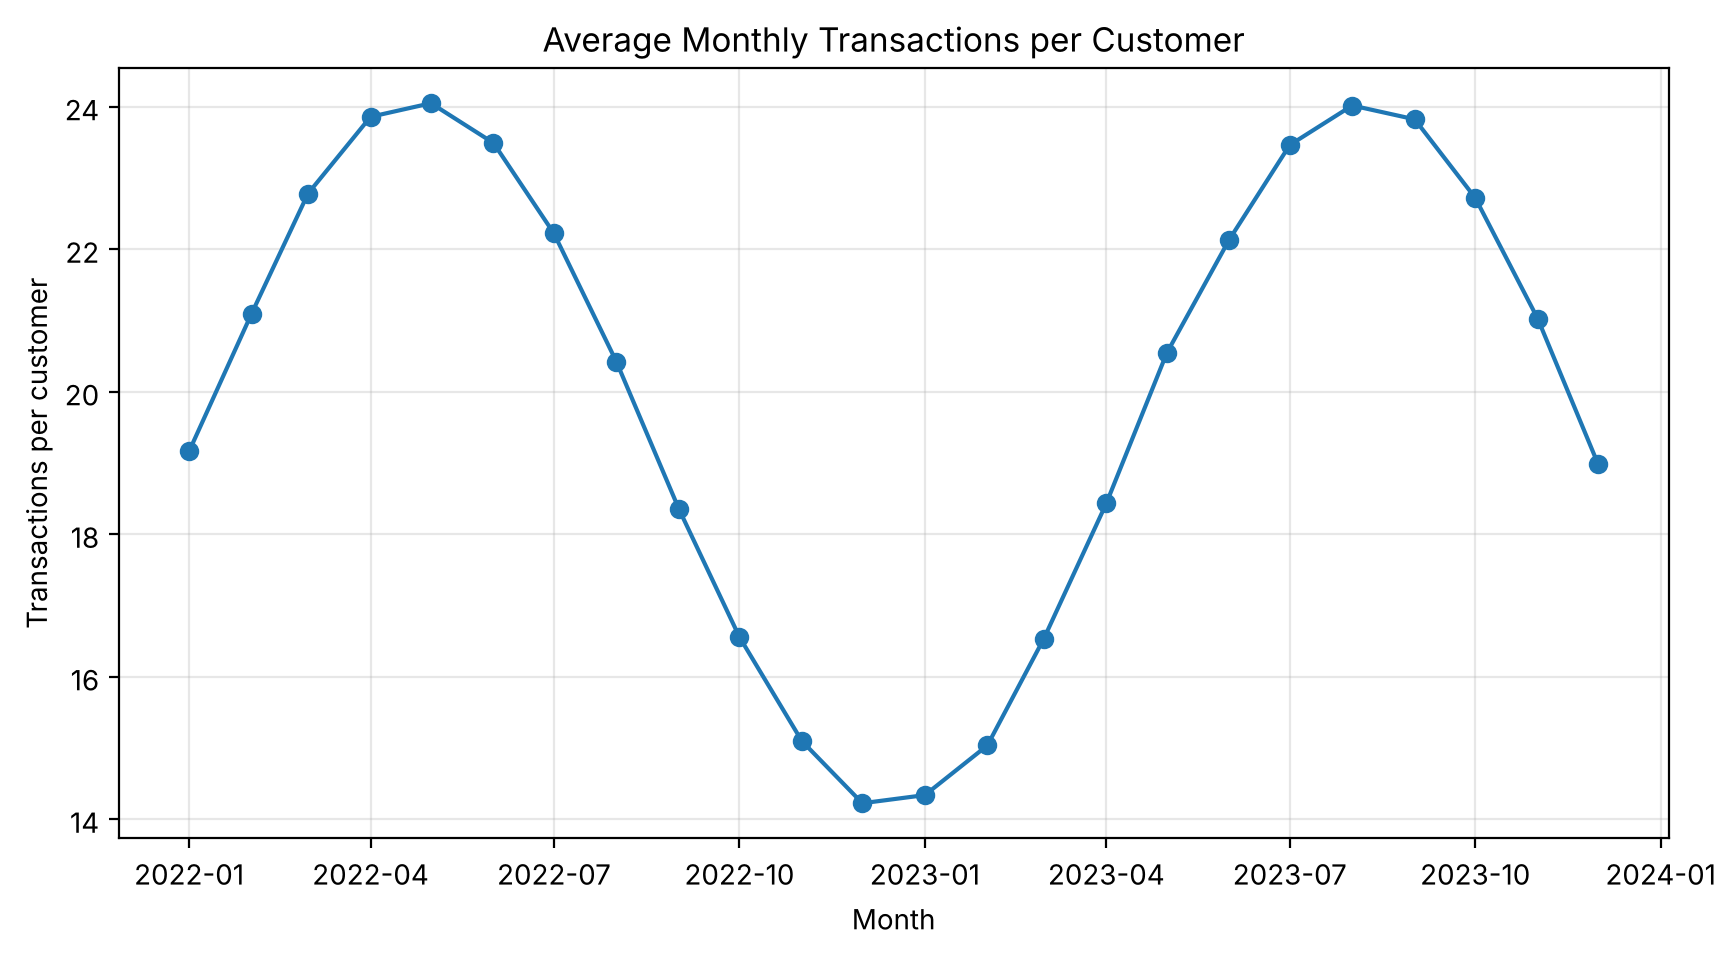

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(monthly.index.to_timestamp(), monthly.values, marker="o")
plt.title("Average Monthly Transactions per Customer")
plt.xlabel("Month")
plt.ylabel("Transactions per customer")
plt.grid(True, alpha=0.3)
plt.show()

In [22]:
from statsmodels.tsa.arima.model import ARIMA

train = monthly[:-6]
test = monthly[-6:]

check_model = ARIMA(train, order=(2, 0, 0)).fit()
predicted = check_model.forecast(6)

comparison = pd.DataFrame({
    "actual": test.round(2),
    "predicted": predicted.round(2),
    "error": (test - predicted).round(2)
})
print(comparison)

mae = np.mean(np.abs(test - predicted))
print("Average error (MAE):", round(mae, 2))

naive = pd.Series(train.iloc[-1], index=test.index)
print("Average error if we just repeat the last value:", round(np.mean(np.abs(test - naive)), 2))

         actual  predicted  error
2023-07   23.46      23.21   0.26
2023-08   24.02      23.58   0.44
2023-09   23.82      23.20   0.63
2023-10   22.72      22.13   0.60
2023-11   21.03      20.54   0.48
2023-12   18.98      18.72   0.26
Average error (MAE): 0.44
Average error if we just repeat the last value: 1.62


In [23]:
final_model = ARIMA(monthly, order=(2, 0, 0)).fit()

forecast = final_model.get_forecast(steps=6)
conf = forecast.conf_int(alpha=0.05)

forecast_df = pd.DataFrame({
    "forecast": forecast.predicted_mean,
    "lower": conf.iloc[:, 0],
    "upper": conf.iloc[:, 1]
}).round(2)

print(forecast_df)

         forecast  lower  upper
2024-01     16.97  16.73  17.20
2024-02     15.31  14.82  15.80
2024-03     14.30  13.56  15.04
2024-04     14.09  13.14  15.03
2024-05     14.71  13.64  15.79
2024-06     16.07  14.93  17.20


Python showed a convergence warning for the final model. The test on the last 6 known months gave a small error (0.44), so I still use the forecast, but I note this as a limitation.

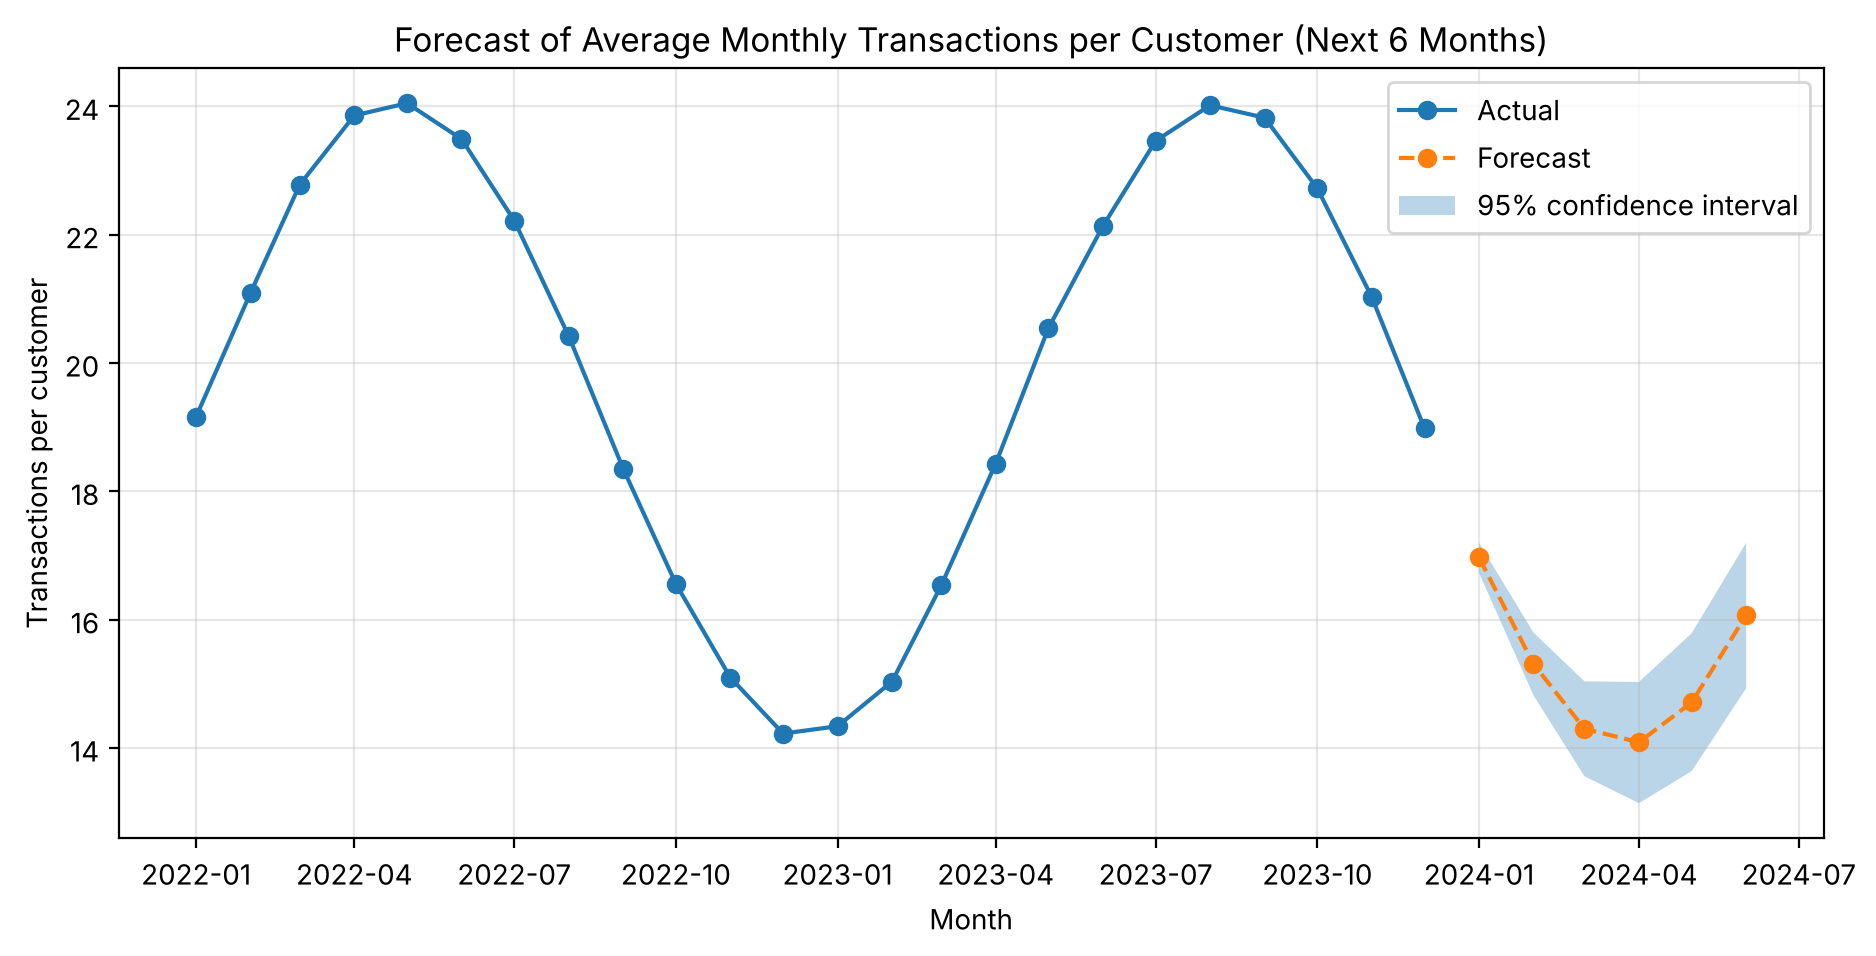

In [24]:
plt.figure(figsize=(11, 5))

plt.plot(monthly.index.to_timestamp(), monthly.values, marker="o", label="Actual")
plt.plot(forecast_df.index.to_timestamp(), forecast_df["forecast"],
         marker="o", linestyle="--", label="Forecast")
plt.fill_between(forecast_df.index.to_timestamp(),
                 forecast_df["lower"], forecast_df["upper"],
                 alpha=0.3, label="95% confidence interval")

plt.title("Forecast of Average Monthly Transactions per Customer (Next 6 Months)")
plt.xlabel("Month")
plt.ylabel("Transactions per customer")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Forecast Interpretation and Business Implications

### What the forecast shows

I used the average number of transactions per customer each month (24 months, January 2022 to December 2023) and forecasted the next 6 months with an ARIMA(2,0,0) model.

- Transactions go up and down in a wave. The peaks were 24.05 (May 2022) and 24.02 (August 2023). The low was 14.23 (December 2022). One full wave takes about 15 months.
- At the end of 2023 the numbers were falling (22.72 in October, 21.03 in November, 18.98 in December).
- The model expects this fall to continue. The forecast goes from 16.97 in January 2024 to a low of about 14.09 in April 2024. After that it starts to recover, reaching about 16.07 in June 2024.
- The April 2024 low is about 41% below the August 2023 peak.

### What the bank should do

1. **Plan for the quiet months.** Transactions will be lowest around March to April 2024. This is a good time for system maintenance and upgrades, because fewer customers will be affected.
2. **Run engagement campaigns before and during the low period.** For example, cashback offers, reminders to use the mobile app, or special deals. The goal is to make the fall less deep.
3. **Focus on customers who are valuable but quiet.** In my feature work, 274 customers have a high balance but low activity (high_value_low_engagement). When overall activity falls, these customers are the most important to keep and re-engage.
4. **Prepare for the recovery.** Since the wave goes up again, server capacity, ATM cash and staff should be ready before activity rises toward the next peak.

### Uncertainties and risks

- **Little history.** The model has seen only 24 months, which is about one and a half waves. It has not seen many repeats of the pattern.
- **The confidence interval may be too narrow.** The past data is very smooth, so the model is very confident. Real banking data is usually noisier, so the true range could be wider.
- **Outside events are not in the model.** Festivals, salary cycles, new offers, a competitor, an app outage or an economic change can break the pattern.
- **Sample and averages.** The transactions file covers only 1,000 customers, and an average can hide differences between customer groups.
- **Small bias.** In my test on the last 6 known months, the model predicted a little lower than the actual value every time (average error 0.44 transactions, compared with 1.62 for a simple "repeat the last value" guess).
- **Uncertainty grows with time.** The shaded band becomes wider in later months, so the January forecast is more reliable than the June forecast.

### What I would monitor

- Each month, compare the actual average transactions with the forecast. If the actual value falls outside the 95% interval, investigate.
- Track the forecast error (MAE) every month. If it grows, retrain the model with the new data.
- Track the numbers separately by channel (mobile, online, branch, ATM) and by customer group, to see where a change starts.
- Track the share of active customers and the number of high-value, low-engagement customers.

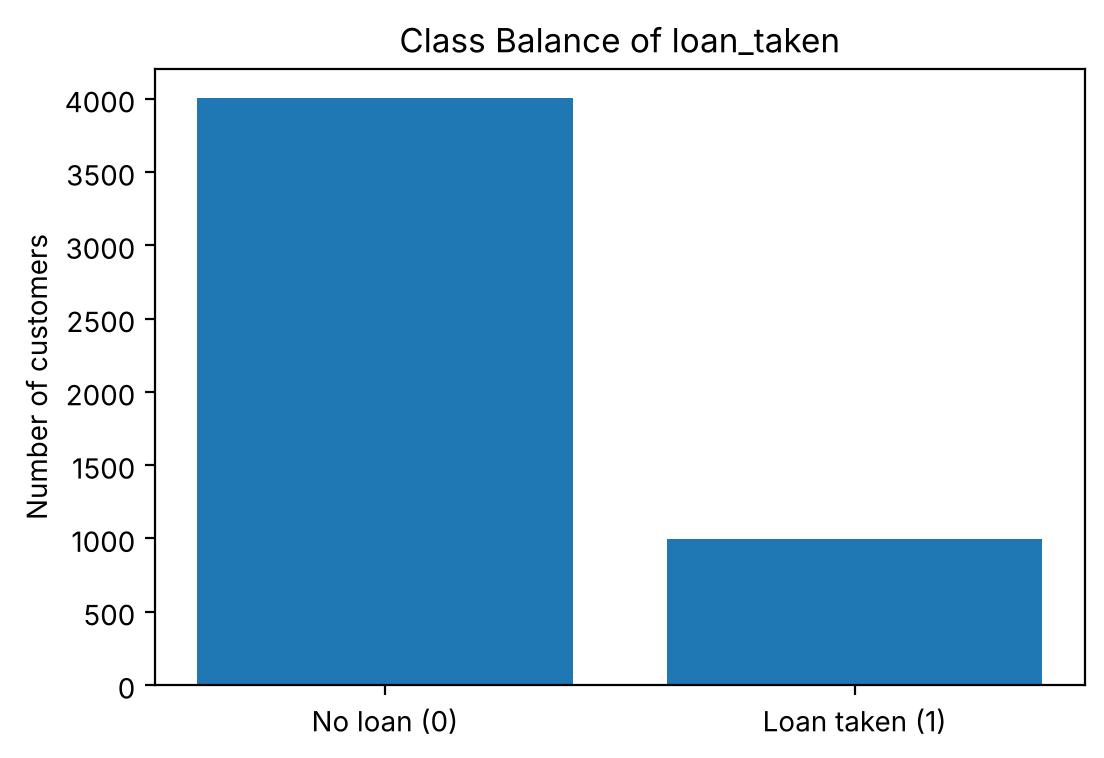

In [25]:
counts = df["loan_taken"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No loan (0)", "Loan taken (1)"], counts.values)
plt.title("Class Balance of loan_taken")
plt.ylabel("Number of customers")
plt.show()

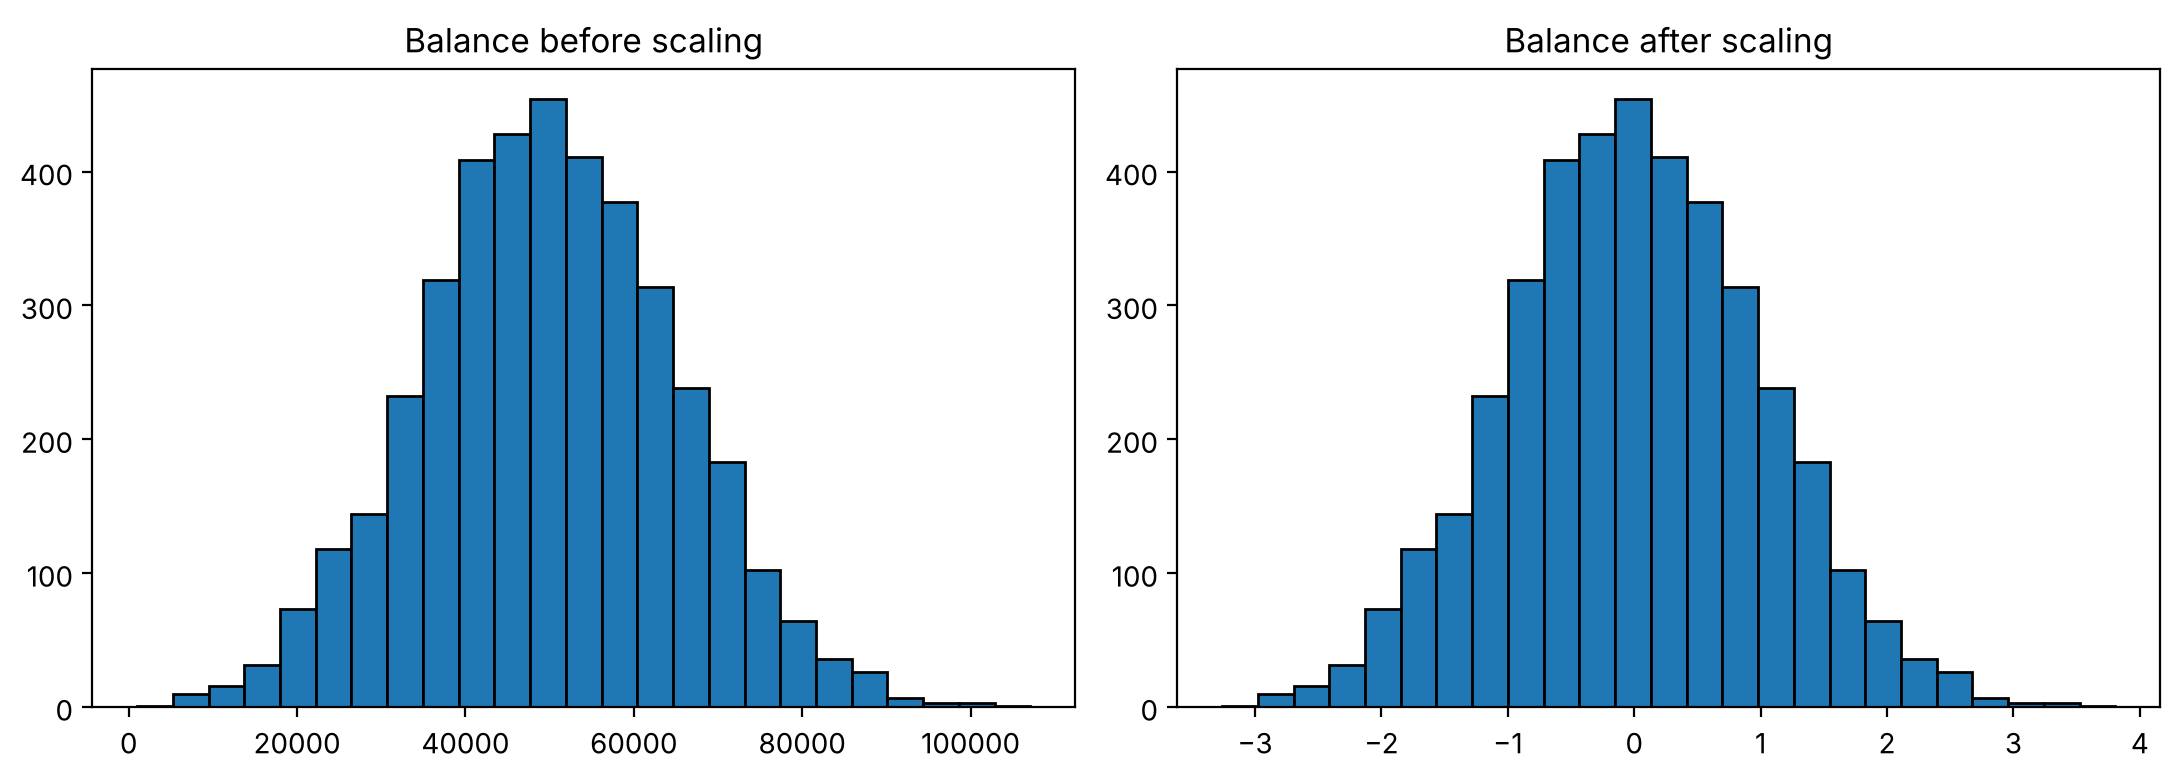

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(X_train["avg_monthly_balance"], bins=25, edgecolor="black")
axes[0].set_title("Balance before scaling")

axes[1].hist(X_train_scaled["avg_monthly_balance"], bins=25, edgecolor="black")
axes[1].set_title("Balance after scaling")

plt.tight_layout()
plt.show()

## Conclusion

- I created 8 new features and 9 one-hot columns. The final table has 23 input features and 1 target (loan_taken).
- Text columns were encoded (one-hot for region and channel, ordered numbers for activity band), and 8 numeric columns were scaled using StandardScaler, fitted on training data only.
- The target loan_taken has about 20% positive cases, so accuracy alone will not be enough to judge models. Precision, recall and F1-score should be used in the next module.
- The data was split 80/20 (4,000 training and 1,000 test customers) with the same loan percentage in both sets.
- The features show very weak relationships with the target, so model performance may be limited. This comes from the data, not from the preparation steps.
- The forecast shows average monthly transactions falling to about 14 in April 2024 and recovering to about 16 by June 2024.